<a href="https://colab.research.google.com/github/FadhilTaufiqurrachman/Machine-Learning/blob/main/244107020090_Fadhil_Taufiqurrachman_T13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Praktikum Jobsheet 13

NIM : 244107020090

Nama : Fadhil Taufiqurrachman

Kelas : TI 3G

No Absen : 06

Mata Kuliah : Pembelajaran Mesin

Persiapan Data

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')
BASE_PATH = '/content/drive/MyDrive/Education/Current Semester College File /Machine Learning/'

Mounted at /content/drive


Import Library

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical

print(f"TensorFlow Versi: {tf.__version__}")

TensorFlow Versi: 2.21.0


Load Dataset MNIST, Normalisasi, dan One-Hot Encoding

In [ ]:
# Memuat Dataset MNIST Dari Keras
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normalisasi Nilai Piksel Dari Rentang 0-255 Menjadi 0-1
X_train = X_train / 255.0
X_test = X_test / 255.0

# Melakukan One-Hot Encoding Pada Label Menjadi 10 Kelas
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

print(f"Bentuk X_train: {X_train.shape} | Bentuk y_train: {y_train.shape}")
print(f"Bentuk X_test : {X_test.shape}  | Bentuk y_test : {y_test.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Bentuk X_train: (60000, 28, 28) | Bentuk y_train: (60000, 10)
Bentuk X_test : (10000, 28, 28)  | Bentuk y_test : (10000, 10)


Bangun Model JST (2 Hidden Layer)

In [ ]:
# Mengatur Seed Untuk Konsistensi Inisialisasi Bobot
tf.random.set_seed(42)

# Membangun Model JST Baseline Dengan 2 Hidden Layer (ReLU)
model_baseline = Sequential([
    # Mengubah Gambar 28x28 Menjadi Vektor 1D (784 Fitur)
    Flatten(input_shape=(28, 28)),
    # Hidden Layer 1
    Dense(128, activation='relu'),
    # Hidden Layer 2
    Dense(64, activation='relu'),
    # Output Layer (10 Kelas Angka 0-9)
    Dense(10, activation='softmax')
])

model_baseline.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Kompilasi Model

In [ ]:
# Mengompilasi Model Dengan Optimizer Adam Dan Loss Categorical Crossentropy
model_baseline.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
print("Model Baseline Berhasil Dikompilasi!")

Model Baseline Berhasil Dikompilasi!


Latih Model Baseline

In [ ]:
# Mencatat Waktu Mulai Pelatihan
start_time = time.time()

# Melatih Model Pada Data Latih Dengan Validasi 10%
history_baseline = model_baseline.fit(
    X_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

# Menghitung Total Durasi Pelatihan Dalam Detik
time_baseline = time.time() - start_time
print(f"\nWaktu Pelatihan Baseline: {time_baseline:.2f} detik")

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.9004 - loss: 0.3510 - val_accuracy: 0.9563 - val_loss: 0.1454
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9562 - loss: 0.1483 - val_accuracy: 0.9668 - val_loss: 0.1066
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9696 - loss: 0.1031 - val_accuracy: 0.9717 - val_loss: 0.0951
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9773 - loss: 0.0775 - val_accuracy: 0.9727 - val_loss: 0.0886
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9833 - loss: 0.0595 - val_accuracy: 0.9760 - val_loss: 0.0808
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9873 - loss: 0.0461 - val_accuracy: 0.9758 - val_loss: 0.0766
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9905 - loss: 0.0358 - val_accuracy: 0.9770 - val_loss: 0.0740
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9929 - loss: 0.0280 - val_accuracy: 0

Evaluasi Model Baseline

In [ ]:
# Mengevaluasi Kinerja Model Pada Data Uji
loss_baseline, acc_baseline = model_baseline.evaluate(X_test, y_test, verbose=0)
print(f"Loss pada data uji    : {loss_baseline:.4f}")
print(f"Akurasi pada data uji : {acc_baseline:.4f}")

Loss pada data uji    : 0.0849
Akurasi pada data uji : 0.9761


**Eksperimen 1 - Ubah Jumlah Neuron Hidden Layer (256 dan 128)**

In [ ]:
tf.random.set_seed(42)

# Membangun Model Dengan 256 Dan 128 Neuron Di Hidden Layer
model_exp1 = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

# Kompilasi Model Eksperimen 1
model_exp1.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Melatih Model Dan Mencatat Waktu Pelatihan
start_time = time.time()
history_exp1 = model_exp1.fit(
    X_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=0
)
time_exp1 = time.time() - start_time

# Evaluasi Pada Data Uji
loss_exp1, acc_exp1 = model_exp1.evaluate(X_test, y_test, verbose=0)
print(f"[Eksperimen 1: 256-128 ReLU]")
print(f"Waktu Pelatihan : {time_exp1:.2f} detik")
print(f"Loss Uji        : {loss_exp1:.4f}")
print(f"Akurasi Uji     : {acc_exp1:.4f}")

[Eksperimen 1: 256-128 ReLU]
Waktu Pelatihan : 54.93 detik
Loss Uji        : 0.0918
Akurasi Uji     : 0.9754


**Eksperimen 2 - Tambah Satu Hidden Layer Lagi (3 Hidden Layer)**

In [ ]:
tf.random.set_seed(42)

# Membangun Model Dengan 3 Hidden Layer (ReLU)
model_exp2 = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

# Kompilasi Model Eksperimen 2
model_exp2.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Melatih Model Dan Mencatat Waktu Pelatihan
start_time = time.time()
history_exp2 = model_exp2.fit(
    X_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=0
)
time_exp2 = time.time() - start_time

# Evaluasi Pada Data Uji
loss_exp2, acc_exp2 = model_exp2.evaluate(X_test, y_test, verbose=0)
print(f"[Eksperimen 2: 256-128-64 ReLU (3 Hidden Layer)]")
print(f"Waktu Pelatihan : {time_exp2:.2f} detik")
print(f"Loss Uji        : {loss_exp2:.4f}")
print(f"Akurasi Uji     : {acc_exp2:.4f}")

[Eksperimen 2: 256-128-64 ReLU (3 Hidden Layer)]
Waktu Pelatihan : 42.41 detik
Loss Uji        : 0.0933
Akurasi Uji     : 0.9789


**Eksperimen 3 - Fungsi Aktivasi Sigmoid vs ReLU**

In [ ]:
tf.random.set_seed(42)

# Membangun Model Dengan Arsitektur Identik Baseline (128-64) Menggunakan Sigmoid
model_sigmoid = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='sigmoid'),
    Dense(64, activation='sigmoid'),
    Dense(10, activation='softmax')
])

# Kompilasi Model Sigmoid
model_sigmoid.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Melatih Model Sigmoid Dan Mencatat Waktu Pelatihan
start_time = time.time()
history_sigmoid = model_sigmoid.fit(
    X_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=0
)
time_sigmoid = time.time() - start_time

# Evaluasi Pada Data Uji
loss_sigmoid, acc_sigmoid = model_sigmoid.evaluate(X_test, y_test, verbose=0)
print(f"[Eksperimen 3: 128-64 Sigmoid]")
print(f"Waktu Pelatihan : {time_sigmoid:.2f} detik")
print(f"Loss Uji        : {loss_sigmoid:.4f}")
print(f"Akurasi Uji     : {acc_sigmoid:.4f}")

[Eksperimen 3: 128-64 Sigmoid]
Waktu Pelatihan : 30.63 detik
Loss Uji        : 0.0912
Akurasi Uji     : 0.9720


**Perbandingan Akurasi, Loss, dan Waktu Pelatihan (Tabel & Grafik)**

=== Tabel Perbandingan Eksperimen JST MNIST ===

                   Model  Hidden Layer Aktivasi  Test Loss  Test Accuracy  Waktu Pelatihan (detik)
 Baseline (128-64, ReLU)             2     ReLU   0.084873         0.9761                36.563937
   Exp 1 (256-128, ReLU)             2     ReLU   0.091836         0.9754                54.925902
Exp 2 (256-128-64, ReLU)             3     ReLU   0.093316         0.9789                42.412139
 Exp 3 (128-64, Sigmoid)             2  Sigmoid   0.091238         0.9720                30.626695


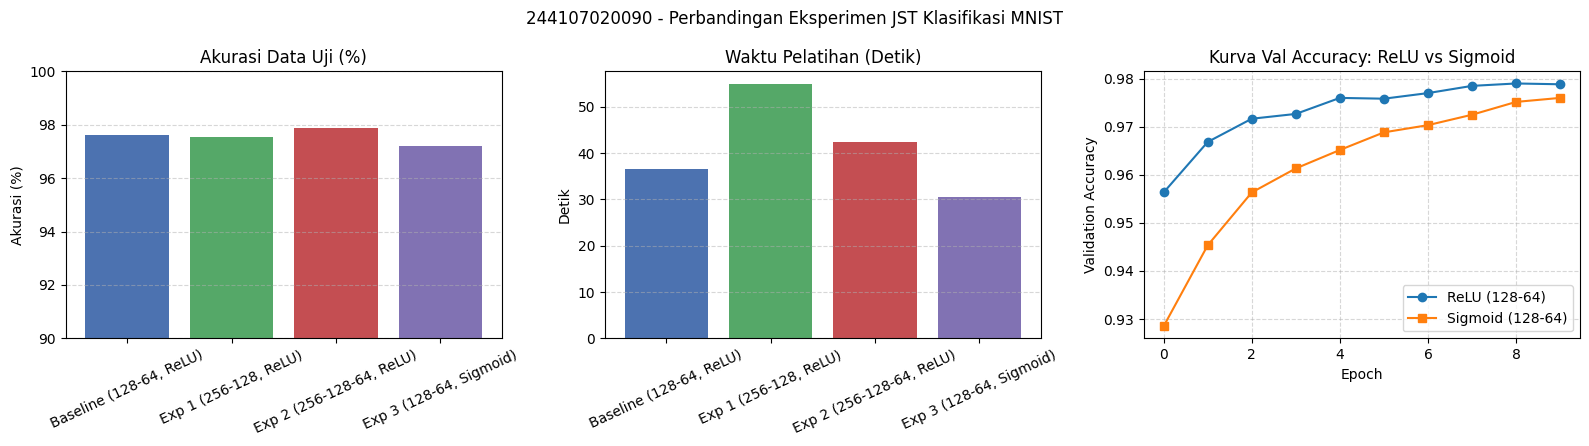

In [ ]:
# Menyusun Tabel Perbandingan Seluruh Skenario Eksperimen
df_hasil = pd.DataFrame({
    'Model': [
        'Baseline (128-64, ReLU)',
        'Exp 1 (256-128, ReLU)',
        'Exp 2 (256-128-64, ReLU)',
        'Exp 3 (128-64, Sigmoid)'
    ],
    'Hidden Layer': [2, 2, 3, 2],
    'Aktivasi': ['ReLU', 'ReLU', 'ReLU', 'Sigmoid'],
    'Test Loss': [loss_baseline, loss_exp1, loss_exp2, loss_sigmoid],
    'Test Accuracy': [acc_baseline, acc_exp1, acc_exp2, acc_sigmoid],
    'Waktu Pelatihan (detik)': [time_baseline, time_exp1, time_exp2, time_sigmoid]
})

print("=== Tabel Perbandingan Eksperimen JST MNIST ===\n")
print(df_hasil.to_string(index=False))

# Visualisasi Perbandingan Akurasi Uji, Waktu Pelatihan, Dan Kurva Sigmoid Vs ReLU
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
fig.suptitle('244107020090 - Perbandingan Eksperimen JST Klasifikasi MNIST')

# Grafik 1: Perbandingan Akurasi Uji
axes[0].bar(df_hasil['Model'], df_hasil['Test Accuracy'] * 100, color=['#4C72B0', '#55A868', '#C44E52', '#8172B3'])
axes[0].set_title('Akurasi Data Uji (%)')
axes[0].set_ylabel('Akurasi (%)')
axes[0].set_ylim(90, 100)
axes[0].tick_params(axis='x', rotation=25)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Grafik 2: Perbandingan Waktu Pelatihan
axes[1].bar(df_hasil['Model'], df_hasil['Waktu Pelatihan (detik)'], color=['#4C72B0', '#55A868', '#C44E52', '#8172B3'])
axes[1].set_title('Waktu Pelatihan (Detik)')
axes[1].set_ylabel('Detik')
axes[1].tick_params(axis='x', rotation=25)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

# Grafik 3: Kurva Validasi ReLU Vs Sigmoid (Arsitektur 128-64)
axes[2].plot(history_baseline.history['val_accuracy'], label='ReLU (128-64)', marker='o')
axes[2].plot(history_sigmoid.history['val_accuracy'], label='Sigmoid (128-64)', marker='s')
axes[2].set_title('Kurva Val Accuracy: ReLU vs Sigmoid')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Validation Accuracy')
axes[2].legend()
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Memperbesar jumlah neuron menjadi 256 dan 128 serta menambah hidden layer ketiga (256-128-64) meningkatkan jumlah parameter bobot yang dilatih sehingga durasi pelatihan bertambah lebih lama dengan peningkatan akurasi uji yang tipis karena dataset MNIST sudah cukup terwakili dengan baik oleh arsitektur dua lapis. Sementara itu, perbandingan langsung pada arsitektur 128-64 memperlihatkan bahwa aktivasi ReLU mencapai konvergensi jauh lebih cepat dan menghasilkan akurasi uji lebih tinggi dibanding Sigmoid dalam 10 epoch, sebab operasi eksponensial Sigmoid lebih berat secara komputasi sekaligus rentan mengalami pengecilan gradien (vanishing gradient) saat perambatan balik.